In [165]:
from collections.abc import Iterable

import ipywidgets
import numpy as np
import PIL.Image
import torch
import torch.nn as nn
import urllib.request
from matplotlib import pyplot as plt
from PIL import ImageEnhance
from torch import Tensor

## 1D convolution

In [166]:
L = 100  # Sequence length
C = 1  # Channels

In [167]:
def plot_signals(**kwargs: Tensor) -> None:
    plt.figure(figsize=(12, 4))
    for label, signal in kwargs.items():
        plt.plot(
            signal.detach().squeeze().numpy(),
            marker=".",
            label=label,
            alpha=0.7,
            linewidth=0.2,
        )
    plt.legend()
    plt.axhline(y=0, color="k", zorder=0, alpha=0.5, lw=1)
    plt.axvline(x=L / 2, color="k", zorder=0, alpha=0.5, lw=1)
    plt.show()

#### Examples

As the input sequence, let's take brown noise + a step function.

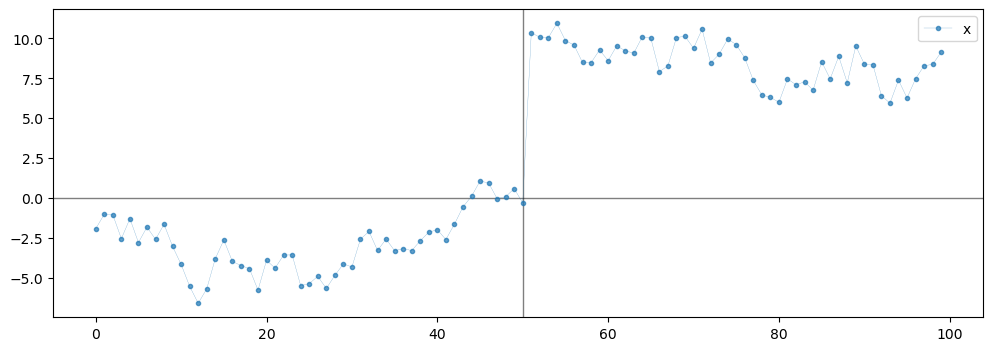

In [168]:
torch.manual_seed(30)
x = torch.randn(1, C, L).cumsum(dim=-1) + 10 * (
    torch.arange(L) > L / 2
).float().reshape(1, 1, -1)

plot_signals(x=x)

In [169]:
def convolve_1d(x: Tensor, kernel: Iterable[float]) -> Tensor:
    kernel = list(kernel)
    conv = nn.Conv1d(
        in_channels=C,
        out_channels=C,
        kernel_size=len(kernel),
        padding=len(kernel) // 2,
        padding_mode="replicate",
        bias=False,
    )
    conv.weight.data.copy_(
        torch.tensor(kernel).reshape(C, C, -1)
    )  # shape (C_out, C_in, kernel_size)
    return conv(x)

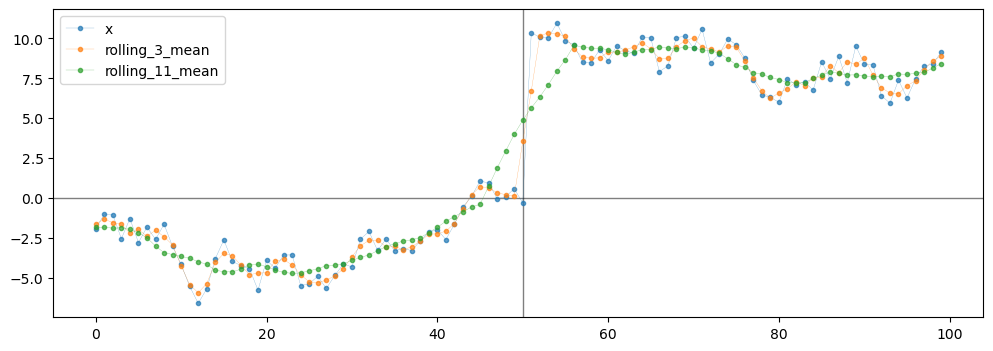

In [170]:
plot_signals(
    x=x,
    rolling_3_mean=convolve_1d(x, [1 / 3, 1 / 3, 1 / 3]),
    rolling_11_mean=convolve_1d(x, [1 / 11] * 11),
)

#### Gaussian kernel

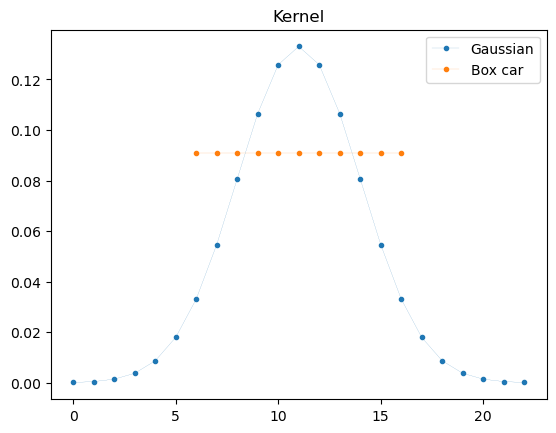

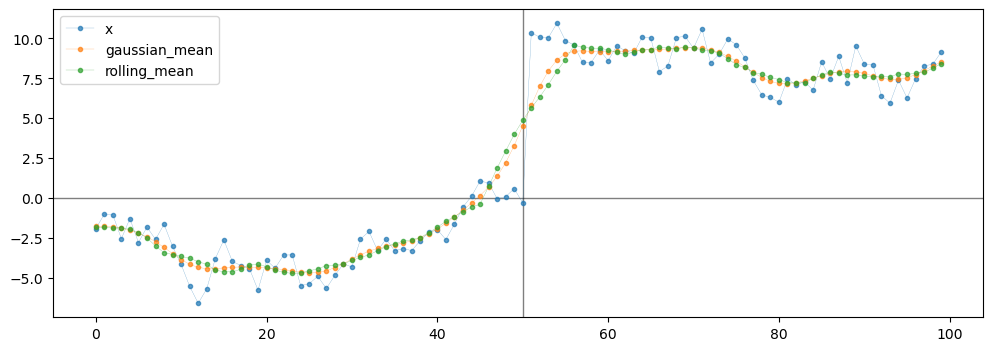

In [171]:
K = 23  # Gaussian kernel size
K2 = K // 2  # Comparable rolling mean kernel size

gaussian_kernel = torch.exp(-(((torch.arange(K) - K // 2) / (K // 6)) ** 2) / 2)
gaussian_kernel = gaussian_kernel / gaussian_kernel.sum()
plt.plot(gaussian_kernel, marker=".", linewidth=0.1, label="Gaussian")
plt.plot(
    list(range(K // 2 - K2 // 2, K // 2 + K2 // 2 + 1)),
    [1 / K2] * K2,
    marker=".",
    linewidth=0.1,
    label="Box car",
)
plt.title("Kernel")
plt.legend()

plot_signals(
    x=x,
    gaussian_mean=convolve_1d(x, gaussian_kernel.tolist()),
    rolling_mean=convolve_1d(x, [1 / K2] * K2),
)

#### Edge detection

In [ ]:
plot_signals(
    x=x,
    conv=convolve_1d(x, [-1, 1]),
)

In [ ]:
plot_signals(x=x, step_detect=convolve_1d(x, [-1, 1]) > 5)

#### Task 1a: sustained step detection
Write a convolution kernel that detects a sustained step in the signal:
the result should be the difference between: the average of 3 values after a given moment, and the average of 3 values before that moment.

In [ ]:
plot_signals(
    x=x,
    sustained_step_detect=convolve_1d(
        x, [...]
    ),
)

#### Task 1b: shift
Write a kernel that shifts the signal by 2 timesteps.

In [ ]:
plot_signals(x=x, shifted=convolve_1d(x, [...]))

#### Task 1c: pattern detection
Use a convolution to detect a given pattern in a binary signal.
The detection should be 1 if the pattern is detected in the window centered on a given timestep, and 0 otherwise.

In [ ]:
torch.manual_seed(30)
x_01 = (torch.randn(1, C, L) > 0).float()

pattern = [1, 0, 1, 1, 0]

plot_signals(x=x_01, detection=...)

## 2D convolution

In [ ]:
C, H, W = 3, 250, 300
img = PIL.Image.open(urllib.request.urlopen("https://http.cat/images/504.jpg")).crop(
    (150, 50, 150 + W, 50 + H)
)
img = ImageEnhance.Contrast(img).enhance(1.5)
img

In [ ]:
assert img.size == (W, H)
assert np.array(img).shape == (H, W, C)

In [ ]:
def convolve_2d(x: Tensor, kernel: Tensor) -> Tensor:
    """For x of shape (C_in, H, W) and kernel of shape (C_out, C_in, kH, kW), result has shape (C_out, H, W)."""
    C_out, C_in, kH, kW = kernel.shape
    conv = nn.Conv2d(
        in_channels=C_in,
        out_channels=C_out,
        kernel_size=(kH, kW),
        padding=(kH // 2, kW // 2),
        padding_mode="replicate",
        bias=False,
    )
    conv.weight.data.copy_(kernel)
    return conv(x).detach()


def convolve_gray(x: Tensor, kernel: Tensor) -> Tensor:
    """For x of shape (C_in, H, W) or (H, W) and kernel of shape (kH, kW), result has shape (H, W)."""
    if x.ndim == 3:
        x = x.mean(dim=0, keepdim=True)  # Convert to grayscale
    else:
        x = x.unsqueeze(0)  # Add C_in dimension.
    kernel = kernel.unsqueeze(0).unsqueeze(0)  # Add C_in=C_out=1 dimensions.
    return convolve_2d(x, kernel).squeeze(0)  # Remove C_out dimension.


def pil_to_tensor(img: PIL.Image.Image) -> Tensor:
    return torch.tensor(np.array(img)).permute(2, 0, 1).float().div(255)  # HWC → CHW


def tensor_to_pil(x: Tensor) -> PIL.Image.Image:
    if x.shape[0] == 1:
        x = x.repeat(3, 1, 1)  # Convert grayscale to RGB.
    return PIL.Image.fromarray(
        (x.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    )  # CHW → HWC


def show_convolved_gray_image(
    img: PIL.Image.Image, kernel: Tensor, colorbar: bool = False
) -> None:
    """Convolve an image with a kernel of shape (kH, kW) (no channel dimension)."""
    x = pil_to_tensor(img)
    y = convolve_gray(x, kernel)

    plt.figure(figsize=(W / 70, H / 70))
    plt.axis("off")
    if colorbar:
        plt.imshow(y.numpy())
        plt.colorbar(fraction=0.04, pad=0)
    else:
        plt.imshow(y.numpy(), vmin=0, vmax=1, cmap="gray")


def show_convolved_rgb_image(img: PIL.Image.Image, kernel: Tensor):
    """Convolve an RGB image with a kernel of shape (C_out=3, C_in=3, kH, kW)."""
    x = pil_to_tensor(img)
    y = convolve_2d(x, kernel)

    plt.figure(figsize=(W / 70, H / 70))
    plt.axis("off")
    plt.imshow(tensor_to_pil(y))

#### Examples: blur

In [ ]:
kH, kW = 15, 15
show_convolved_gray_image(img, torch.full((kH, kW), 1 / (kH * kW)))

In [ ]:
kH, kW = 1, 50
show_convolved_gray_image(img, torch.full((kH, kW), 1 / (kH * kW)))

#### Gaussian blur

In [ ]:
kH, kW = K, K
y, x = torch.meshgrid(torch.arange(kH), torch.arange(kW), indexing="ij")
y = y - K // 2
x = x - K // 2
gaussian_kernel_2d = torch.exp(-((x**2 + y**2) / (K // 6) ** 2) / 2)
gaussian_kernel_2d = gaussian_kernel_2d / gaussian_kernel_2d.sum()
plt.imshow(gaussian_kernel_2d.numpy())
show_convolved_gray_image(img, gaussian_kernel_2d)

Gaussian blur can be implemented much faster, by first blurring in the horizontal direction and then in the vertical direction, using the 1D Gaussian kernel. (This is called a separable convolution.)
$$ e^{- \frac{x^2 + y^2}{2 \sigma^2}} = e^{- \frac{x^2}{2 \sigma^2}} \cdot e^{- \frac{y^2}{2 \sigma^2}} $$

In [ ]:
print(torch.allclose(gaussian_kernel_2d, torch.outer(gaussian_kernel, gaussian_kernel)))


#### Shift

In [ ]:
show_convolved_gray_image(img, torch.diag(torch.tensor([0] * 100 + [1])))

#### Edge detection

In [ ]:
show_convolved_gray_image(img, torch.tensor([[ 0,  0,  0],
                                             [-1, +1,  0],
                                             [ 0,  0,  0]]), colorbar=True)

In [ ]:
show_convolved_gray_image(img, torch.tensor([[ 0,  -1,  0],
                                             [ 0, +1,  0],
                                             [ 0,  0,  0]]), colorbar=True)

In [ ]:
sobel_kernel_x = torch.tensor([[-1, 0, 1],
                               [-2, 0, 2],
                               [-1, 0, 1]])
sobel_kernel_y = sobel_kernel_x.T
show_convolved_gray_image(img, sobel_kernel_y, colorbar=True)

#### Pattern detection

In [ ]:
pattern_img = img.crop((75, 75, 115, 105))
pattern_img

In [ ]:
def show_detection_heatmap(
    brightness: float = pil_to_tensor(img).mean().item(), contrast: float = 0.2
) -> None:
    # Soft-threshold to make image and kernel mostly -1/+1
    new_img = torch.tanh((pil_to_tensor(img).mean(dim=0) - brightness) / contrast)
    kernel = torch.tanh((pil_to_tensor(pattern_img).mean(dim=0) - brightness) / contrast)

    detection = convolve_gray(new_img, kernel) / kernel.pow(2).sum()
    detection_flipped = convolve_gray(new_img, kernel.flip(-1)) / kernel.pow(2).sum()

    _fig, axs = plt.subplots(2, 3, figsize=(9, 5), constrained_layout=True)
    for ax in axs.flatten():
        ax.axis("off")
    axs[0, 0].imshow(img)
    axs[1, 0].imshow(new_img, vmin=-1, vmax=1)
    axs[0, 0].set_title("input (before / after soft-threshold)")
    axs[0, 1].imshow(kernel, vmin=-1, vmax=1)
    axs[1, 1].imshow(kernel.flip(-1), vmin=-1, vmax=1)
    axs[0, 1].set_title("kernel (left eye / flipped)")
    axs[0, 2].imshow(detection, vmin=-0.2, vmax=0.8)
    axs[1, 2].imshow(detection_flipped, vmin=-0.2, vmax=0.8)
    axs[0, 2].set_title("convolution")


show_detection_heatmap()

# ipywidgets.interact(
#     show_detection_heatmap,
#     brightness=ipywidgets.FloatSlider(min=0, max=1, step=0.01, value=0.4),
#     contrast=ipywidgets.FloatSlider(min=0.01, max=0.5, step=0.01, value=1/8),
# );

## Task 2: many channels (RGB)

For a 2D image with many channels, a `kH × kW` kernel is described by a `C_out × C_in × kH × kW` tensor.<br>
Instead of a linear combination of the input window (input $\in \mathbb{R}^{k_H \times k_W}$, output $\in \mathbb{R}$), the result is a linear transformation of the input window: input $\in \mathbb{R}^{C_{in} \times k_H \times k_W}$, output $\in \mathbb{R}^{C_{out}}$.

What kernel will give the following transformations?


#### Identity kernel

In [ ]:
# Hint: 1×1 convolution, transforms each pixel independently, applying an arbitrary linear transformation to the pixel, treating it as a vector of length 3.
show_convolved_rgb_image(img, ...)

#### Average over channels (conversion to grayscale)

In [ ]:
show_convolved_rgb_image(img, ...)

####  Per-channel blur

In [ ]:
kH, kW = 70, 1

show_convolved_rgb_image(img, ...)

#### Channel swap (red ←→ blue)

In [ ]:
show_convolved_rgb_image(img, ...)

#### Chromatic aberration
Shift red channel `s` pixels to the bottom-right, blue channel `s` pixels to the top-left.

In [ ]:
s = 10

show_convolved_rgb_image(img, ...)

## Padding, strides

See [conv_arithmetic](https://github.com/vdumoulin/conv_arithmetic) for visualizations of how padding, stride, and dilation work.

#### Padding

torch.Size([3, 10, 20])

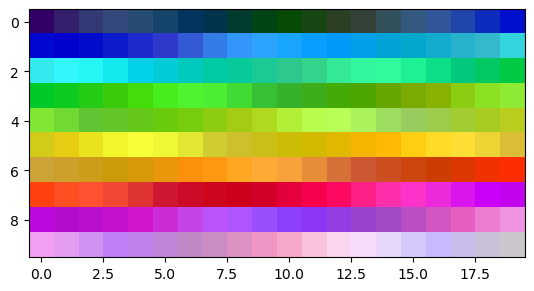

In [172]:
H, W = 10, 20
img2 = torch.tensor((
    0.8 * plt.get_cmap("gist_ncar", H * W)(np.arange(H * W)).reshape(H, W, 4)
    + 0.2 * plt.get_cmap("flag", H * W)(np.arange(H * W)).reshape(H, W, 4)
)).to(torch.float32).permute((2, 0, 1))[:3]  # HWC → CHW, drop alpha channel
plt.imshow(img2.permute((1, 2, 0)))
img2.shape

shape: (3, 10, 20) → (3, 8, 18)


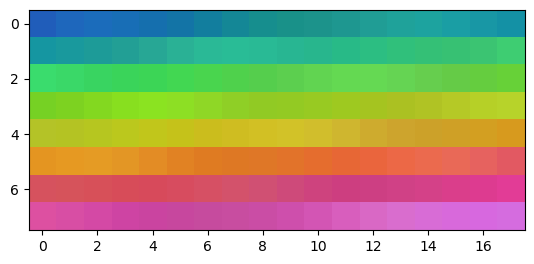

In [173]:
def show_convolved_blur(
    kernel_size: int | tuple[int, int] = (3, 3),
    padding: int | tuple[int, int] =0,
    padding_mode: str = 'zeros',
    stride: int | tuple[int, int] = 1
) -> None:
    kH, kW = kernel_size if isinstance(kernel_size, tuple) else (kernel_size, kernel_size)
    kernel = torch.full((kH, kW), 1 / (kH * kW))
    kernel = torch.eye(3).reshape(3, 3, 1, 1) * kernel.reshape(1, 1, kH, kW)

    conv = nn.Conv2d(in_channels=3, out_channels=3, kernel_size=(kH, kW), padding=padding, padding_mode=padding_mode, stride=stride, bias=False)
    conv.weight.data.copy_(kernel)
    result = conv(img2).detach()
    print(f"shape: {tuple(img2.shape)} → {tuple(result.shape)}")
    plt.imshow(result.permute(1, 2, 0))

show_convolved_blur()

In [ ]:
show_convolved_blur(kernel_size=(5,5))

In [ ]:
show_convolved_blur(kernel_size=(5,5), padding=5 // 2)  # equivalently: padding="same"

In [ ]:
show_convolved_blur(padding=10)

In [ ]:
show_convolved_blur(kernel_size=(1,1), padding=(1, 2), padding_mode='replicate')  # there's also "reflect" and "circular".

#### Stride

In [ ]:
show_convolved_blur(kernel_size=(1,1))

In [ ]:
show_convolved_blur(kernel_size=(1,1), stride=2)

In [ ]:
show_convolved_blur(kernel_size=(5,5), stride=(5,5))  # same as avg-pool